# Problem Set 03 — Đọc dữ liệu trong một dự án AI
**Giảng viên: Nguyễn Bích Vân • IAI-UET-VNU • UET.MAT1052**

Tất cả dữ liệu trong bộ này là **giả lập mới phục vụ học tập**; không mô tả sản phẩm, sinh viên hoặc người dùng thật.

Mở cả thư mục bằng **File → Open Folder**, chọn **Select Kernel**, rồi chạy các ô từ trên xuống.
Kết quả nằm **ngay dưới ô mã**, không phải trong Terminal. Trong ô notebook, **Shift+Enter** chạy ô; dấu `PS ...>` và `>>` không thuộc mã Python.

Nếu thiếu thư viện, tạo ô Code và chạy `%pip install -r requirements.txt`, sau đó **Restart Kernel**. Không tự cài lại mỗi lần Run All.

## Notebook 00 — Học mẫu trước khi làm bài
Các mẫu sử dụng dữ liệu đơn đồ uống riêng. Đây không phải lời giải Bài 6–10.

## Tra cứu nhanh các nhãn tiếng Anh
| Cột | Giá trị và nghĩa |
|---|---|
| `task` | `FAQ`: câu hỏi thường gặp; `Code`: hỗ trợ lập trình; `Summarization`: tóm tắt; `Code explanation`: giải thích mã (tùy tệp). |
| `recording_method` | `Stopwatch`: bấm giờ; `Self-reported`: tự ước lượng. |
| `evaluation_round` | `Round 1`, `Round 2`, `Round 3`: các đợt đánh giá. |
| `input_length_group` | `Short`, `Medium`, `Long`: ngắn, vừa, dài. |
| `processing_mode` | `Standard`: thường; `Economy`: tiết kiệm. |
| `order_type`, `shift` | `Takeaway`/`Dine-in`: mang đi/tại chỗ; `Morning`/`Afternoon`: sáng/chiều. |

Không đổi ô trống thành 0; không trộn CSV cũ với mã mới.


### Tên cột trong dữ liệu học mẫu
| Tên cột | Nghĩa tiếng Việt |
|---|---|
| `id` | Mã đơn đồ uống |
| `order_type` | Kiểu đơn: `Takeaway` hoặc `Dine-in` |
| `wait_time_min` | Thời gian chờ, phút |
| `item_count` | Số món trong đơn |
| `shift` | Ca: `Morning` hoặc `Afternoon` |


## 1. Mở đúng thư mục, chọn đúng kernel

Giải nén toàn bộ gói rồi mở **File → Open Folder** trong VS Code. Chọn thư mục chứa `data/`, không chỉ mở riêng một notebook từ trong ZIP. Cài hai tiện ích **Python** và **Jupyter** của Microsoft nếu máy chưa có.

Mở `00_Learn_Plotnine.ipynb`. Ở góc trên bên phải, bấm **Select Kernel** và chọn Python muốn dùng. Chạy ô đầu tiên để biết kernel đang dùng chương trình nào:

In [1]:
import sys
print(sys.executable)


c:\Users\Pro 5\AppData\Local\Programs\Python\Python313\python.exe


Nếu thiếu thư viện, tạo một ô Code và chạy:

**Chỉ chạy khi cần cài thư viện:**
```python
%pip install -r requirements.txt
```

## 2. Đọc bảng trước khi vẽ

Bộ dữ liệu mẫu `demo_drink_orders.csv` mô tả 24 lượt nhận đồ uống sau một buổi seminar AI. Đây là **ví dụ giả lập học cú pháp**, không phải dữ liệu Bài 6–10. Mỗi hàng là một đơn; `order_type` cho biết mang đi hay tại chỗ, `wait_time_min` là số phút chờ, `item_count` là số món và `shift` là sáng/chiều.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display
from plotnine import (
    ggplot, aes, geom_point, geom_histogram, after_stat,
    geom_rect, geom_bar, geom_col, geom_hline,
    geom_boxplot, geom_line, facet_wrap, labs, scale_x_continuous
)

ROOT = Path.cwd()
DATA = ROOT / "data"
demo = pd.read_csv(DATA / "demo_drink_orders.csv")
display(demo.head())
print("The number of rows, the number of columns:", demo.shape)
print(demo.dtypes)
print(demo.isna().sum())

,id,order_type,wait_time_min,item_count,shift
0,1,Takeaway,2,1,Morning
1,2,Takeaway,3,1,Afternoon
2,3,Takeaway,4,2,Morning
3,4,Takeaway,2,1,Afternoon
4,5,Takeaway,6,3,Morning


The number of rows, the number of columns: (24, 5)
id                int64
order_type       object
wait_time_min     int64
item_count        int64
shift            object
dtype: object
id               0
order_type       0
wait_time_min    0
item_count       0
shift            0
dtype: int64


`Path.cwd()` là thư mục làm việc hiện tại. Notebook không có biến `__file__`. Nếu báo không tìm thấy CSV, in `DATA.resolve()` rồi kiểm tra có mở đúng thư mục không; đừng sửa số liệu hoặc tên cột để né lỗi đường dẫn.

`head()` cho vài dòng đầu, `shape` cho số hàng/cột, `dtypes` cho kiểu dữ liệu, `isna().sum()` đếm ô thiếu theo cột. Cột số có ô thiếu có thể được đọc thành kiểu số thực dù các giá trị quan sát là số nguyên.

Khi phân tích hai cột, chỉ bỏ giá trị thiếu ở các cột thực sự cần dùng:

In [3]:
x = demo.dropna(subset=["order_type", "wait_time_min"]).copy()
print("The number of avoided rows:", len(demo) - len(x))

The number of avoided rows: 0


Không dùng `dropna()` cho toàn bộ bảng nếu việc thiếu một cột không liên quan không nên làm mất quan sát. Không thay thời gian thiếu bằng 0: thiếu thông tin khác với chờ 0 phút.

## 3. Một biểu đồ được xây bằng các lớp

Bắt đầu bằng ba quyết định: bảng nào, biến nào đặt ở đâu, dùng hình gì để biểu diễn. Ví dụ sau vẽ mỗi đơn đồ uống thành một điểm:

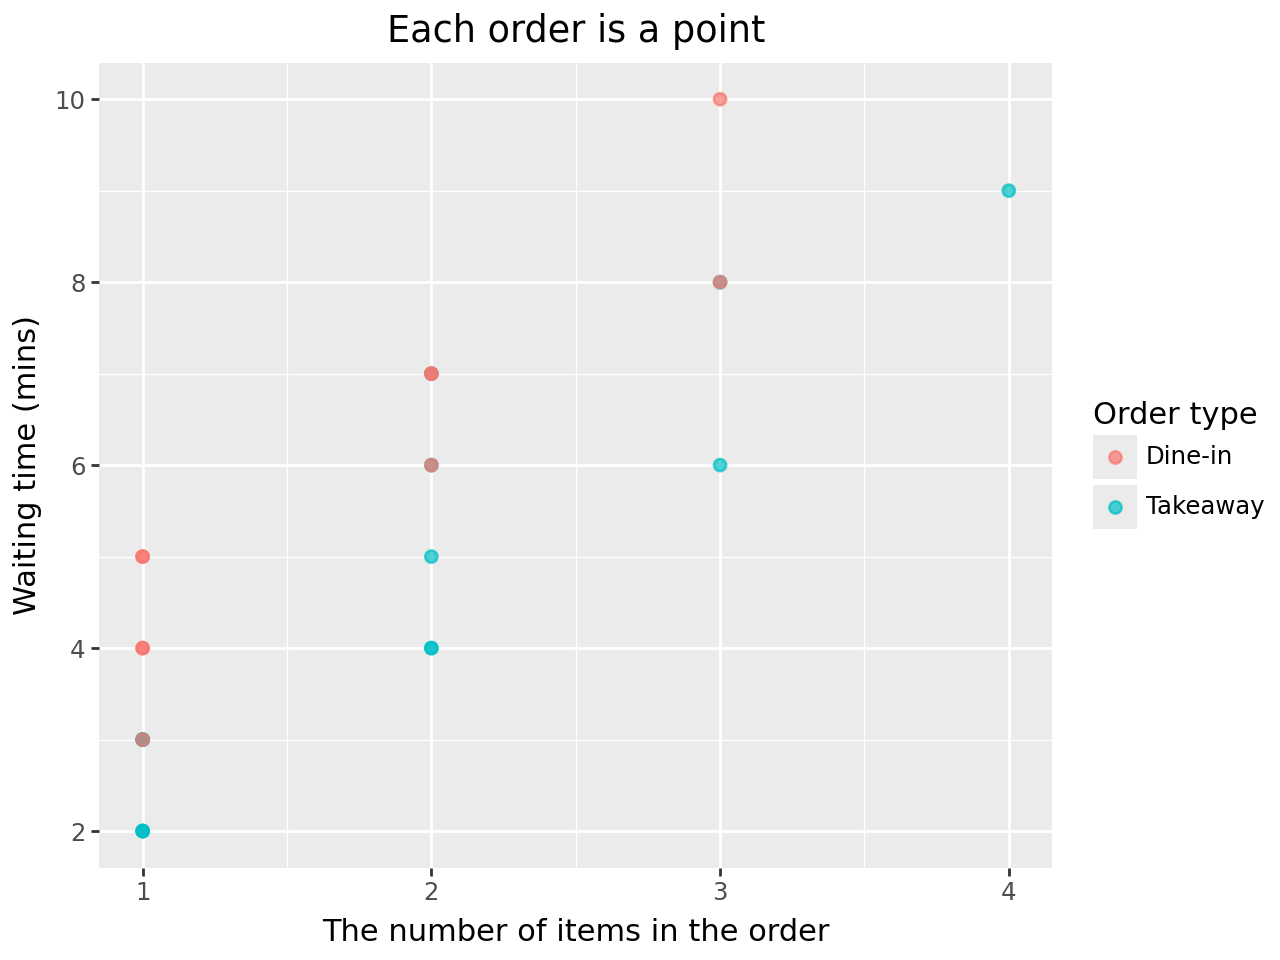

In [4]:
p = (
    ggplot(demo, aes(x="item_count", y="wait_time_min", color="order_type"))
    + geom_point(size=2, alpha=0.7)
    + labs(x="The number of items in the order", y="Waiting time (mins)",
           color="Order type", title="Each order is a point")
)
display(p)

`ggplot(demo,...)` chọn bảng; `aes` ánh xạ số món, thời gian chờ và kiểu đơn tới vị trí/màu; `geom_point` vẽ điểm. `labs` đổi nhãn hiển thị, *không đổi tên cột*. Hai tham số `size` và `alpha` là thiết lập hiển thị. Khi biến nằm trong `aes(color="order_type")`, màu mang thông tin phân nhóm. Tên biến phải đặt trong dấu nháy và khớp CSV.

Dấu cộng nối các lớp; dấu ngoặc ngoài cho phép viết biểu thức trên nhiều dòng. Trong notebook có thể để `p` ở dòng cuối, hoặc dùng `display(p)`; trong vòng lặp nên gọi `display(p)` cho từng hình. Chỉ viết `print(p)` không phải cách chắc chắn để hiện hình.

Sau khi vẽ, lưu hình để nộp:

In [5]:
OUT = ROOT / "example_figures"
OUT.mkdir(exist_ok=True)
p.save(OUT / "scatter.png", width=7, height=4, dpi=150)
p.save(OUT / "scatter.pdf", width=7, height=4)

c:\Users\Pro 5\AppData\Local\Programs\Python\Python313\Lib\site-packages\plotnine\ggplot.py:623: PlotnineWarning: Saving 7 x 4 in image.
c:\Users\Pro 5\AppData\Local\Programs\Python\Python313\Lib\site-packages\plotnine\ggplot.py:624: PlotnineWarning: Filename: d:\XSTK 2026\PS03_AI_Student_English\PS03_AI_Student_English\example_figures\scatter.png
c:\Users\Pro 5\AppData\Local\Programs\Python\Python313\Lib\site-packages\plotnine\ggplot.py:623: PlotnineWarning: Saving 7 x 4 in image.
c:\Users\Pro 5\AppData\Local\Programs\Python\Python313\Lib\site-packages\plotnine\ggplot.py:624: PlotnineWarning: Filename: d:\XSTK 2026\PS03_AI_Student_English\PS03_AI_Student_English\example_figures\scatter.pdf


PNG dễ chèn báo cáo; PDF giữ đồ họa vector. Các lệnh hiển thị và lưu theo hướng dẫn chính thức [1]. Các hình trong gói không cần đặt bảng màu cố định để làm bài.

**Thử thay một thứ:** bỏ ánh xạ màu, giữ các thành phần khác. Những điểm nào vẫn còn và thông tin nào không còn được hiển thị? Đây là cách học nhanh hơn sao chép cả đoạn mà không đọc.

## 4. Lọc, tạo biến và tổng hợp có chủ đích

Ba thao tác sau tác động lên bảng theo ba cách khác nhau:

In [6]:
chon = demo.query("item_count >= 2 and wait_time_min < 8").copy()
chon["long_wait"] = chon["wait_time_min"] >= 6
bang = (
    chon.groupby("order_type", observed=True)
    .agg(n=("id", "size"),
         n_long_wait=("long_wait", "sum"),
         long_wait_rate=("long_wait", "mean"))
    .reset_index()
)
bang["percent"] = 100 * bang["long_wait_rate"]
display(bang)

,order_type,n,n_long_wait,long_wait_rate,percent
0,Dine-in,3,3,1.0,100.0
1,Takeaway,6,3,0.5,50.0


`query` giữ từng hàng thỏa đồng thời hai điều kiện. Dòng gán tạo một biến logic. `groupby` chia các hàng đã giữ theo kiểu đơn; `agg` tóm tắt từng nhóm, nên mỗi hàng kết quả lúc này là *một nhóm*, không còn là một đơn.

`size` đếm số hàng; `count` đếm số giá trị không thiếu của cột được chọn. Với dữ liệu đã bỏ thiếu phù hợp, lấy trung bình biến logic là tỉ lệ đúng. Nếu dùng trực tiếp phép so sánh trên cột có NaN, NaN có thể trở thành False và làm sai mẫu số; vì vậy phải xác định chính sách thiếu *trước* khi tạo biến chỉ báo.

Cách lọc tương đương bằng mặt nạ:

In [7]:
chon = demo.loc[
    (demo["item_count"] >= 2) & (demo["wait_time_min"] < 8)
].copy()

Trong `query` dùng `and/or`; với hai Series dùng `&/|` và đặt ngoặc quanh mỗi điều kiện. Còn `demo[["order_type","wait_time_min"]]` là *chọn cột*, không phải lọc hàng.

**Tự đọc lại bằng lời:** “Trong các đơn có ít nhất hai món và chờ dưới tám phút, mỗi kiểu đơn có bao nhiêu đơn và bao nhiêu phần chờ ít nhất sáu phút?” Nếu câu này không phải câu hỏi muốn nghiên cứu, cần sửa thao tác trước khi vẽ.

## 5. Histogram: biên khoảng và chuẩn hóa

Bản số đếm cho biết số quan sát trong mỗi khoảng. Đặt biên rõ ràng thay vì để phần mềm tự chọn:

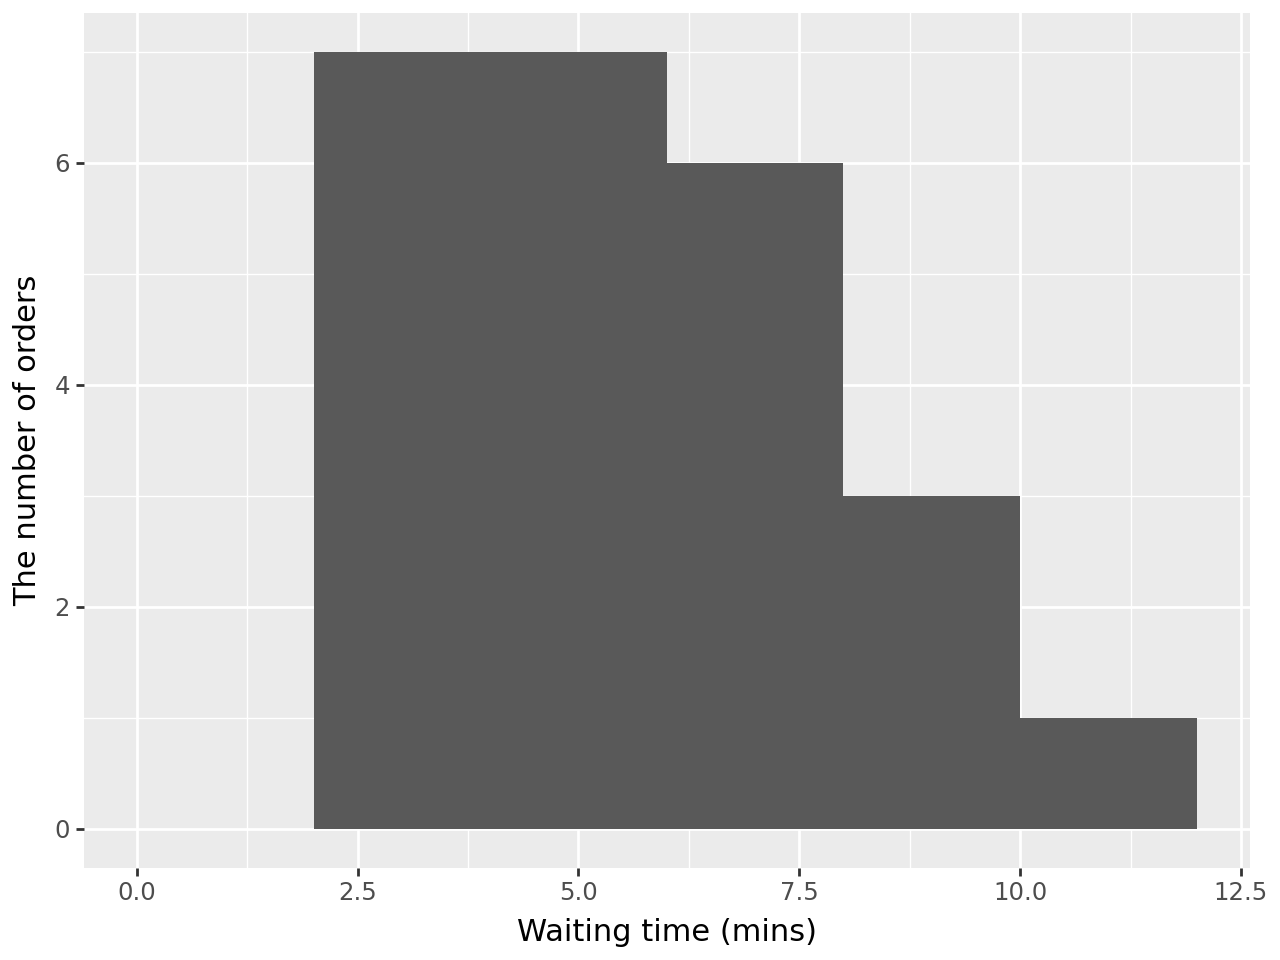

In [ ]:
edges = [0, 2, 4, 6, 8, 10, 12]
p_count = (
    ggplot(demo, aes(x="wait_time_min"))
    + geom_histogram(breaks=edges, closed="left")
    + labs(x="Waiting time (mins)", y="The number of orders")
)
display(p_count)
demo['wait_time_in']

`closed="left"` dùng khoảng lấy đầu trái. Dữ liệu mẫu lớn nhất là 10, nhỏ hơn biên cuối 12. Luôn chọn biên phủ tất cả quan sát cần phân tích; nếu lọc bớt, phải nói rõ tập còn lại. Với NumPy, khoảng cuối của `histogram` có tính đầu phải; các ví dụ Python của bộ này chọn biên cuối lớn hơn max nên khác biệt đó không làm đổi số đếm.

Để diện tích của mỗi histogram là 100%, dùng mật độ phần trăm:

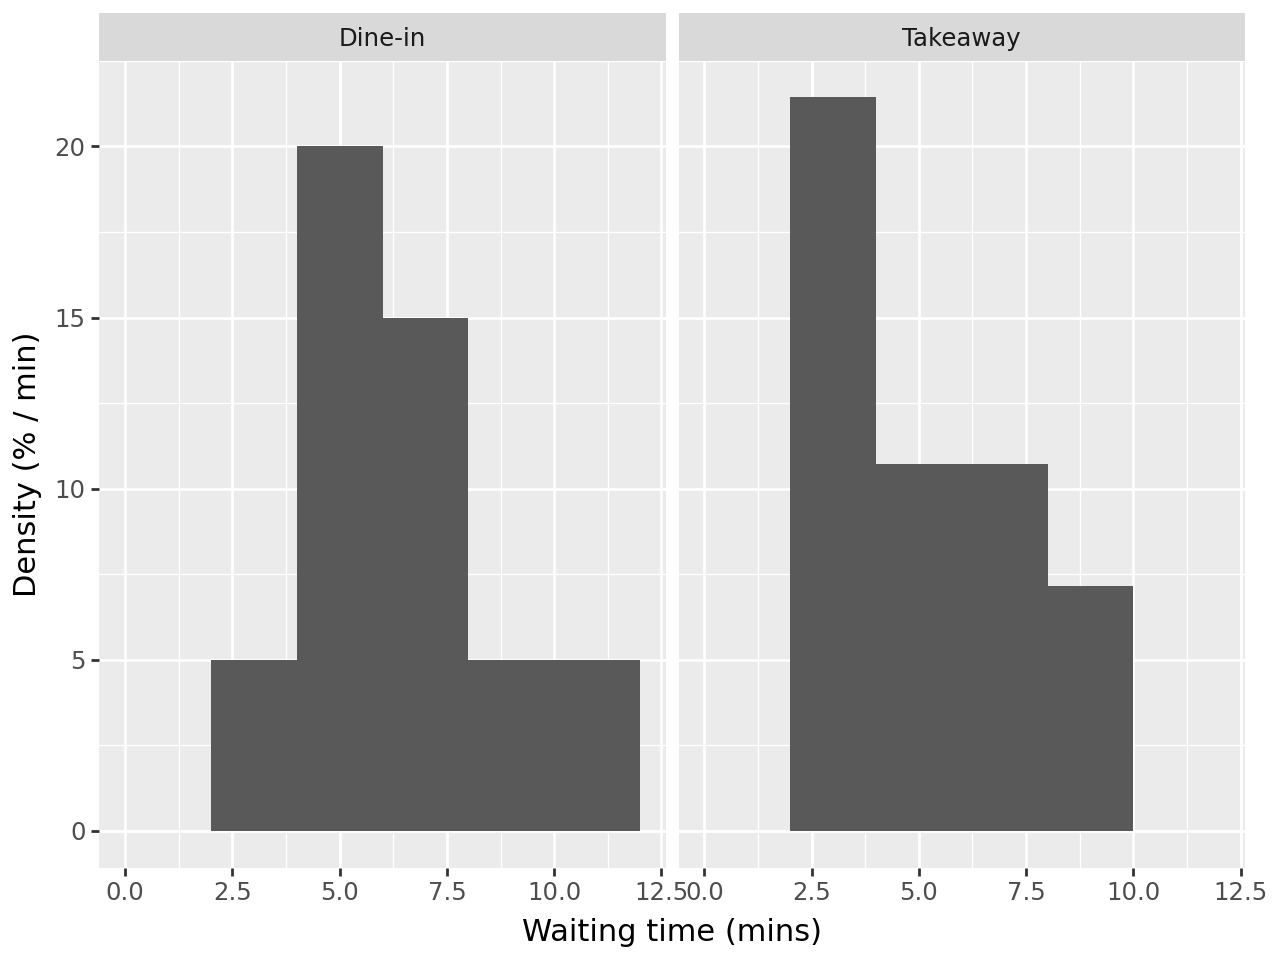

In [9]:
p_density = (
    ggplot(demo, aes(x="wait_time_min", y=after_stat("100*density")))
    + geom_histogram(breaks=edges, closed="left")
    + facet_wrap("~ order_type", scales="fixed")
    + labs(x="Waiting time (mins)", y="Density (% / min)")
)
display(p_density)

`after_stat` lấy kết quả sau phép đếm của lớp histogram. Trong từng ô phân nhỏ, mật độ được chuẩn hóa theo dữ liệu của ô; giữ `scales="fixed"` để các trục so sánh trực tiếp. Không dùng `ncount` thay mật độ: đưa cột cao nhất về 1 không đồng nghĩa tổng diện tích bằng 1 [2–3].

**Công thức để đối chiếu:** nếu $n_j$ quan sát nằm trong khoảng rộng $\Delta_j$, trên $n$ quan sát hợp lệ, thì $h_j=100n_j/(n\Delta_j)$. Chiều cao mang đơn vị \%/đơn vị trục ngang. $100n_j/n$ là phần trăm *cả khoảng*, không phải mật độ khi $\Delta_j\ne1$.

## 6. Tự tính mật độ để nhìn rõ mẫu số

Với khoảng không đều, có thể lập bảng bằng NumPy rồi vẽ các hình chữ nhật bằng `geom_rect`. Cách này giúp kiểm tra độc lập với thống kê tự động của plotnine:

,bin_left,bin_right,n,percent,percent_density
0,0,3,3,12.500000,4.166667
1,3,5,8,33.333333,16.666667
2,5,9,11,45.833333,11.458333
3,9,12,2,8.333333,2.777778


Total area: 100.0


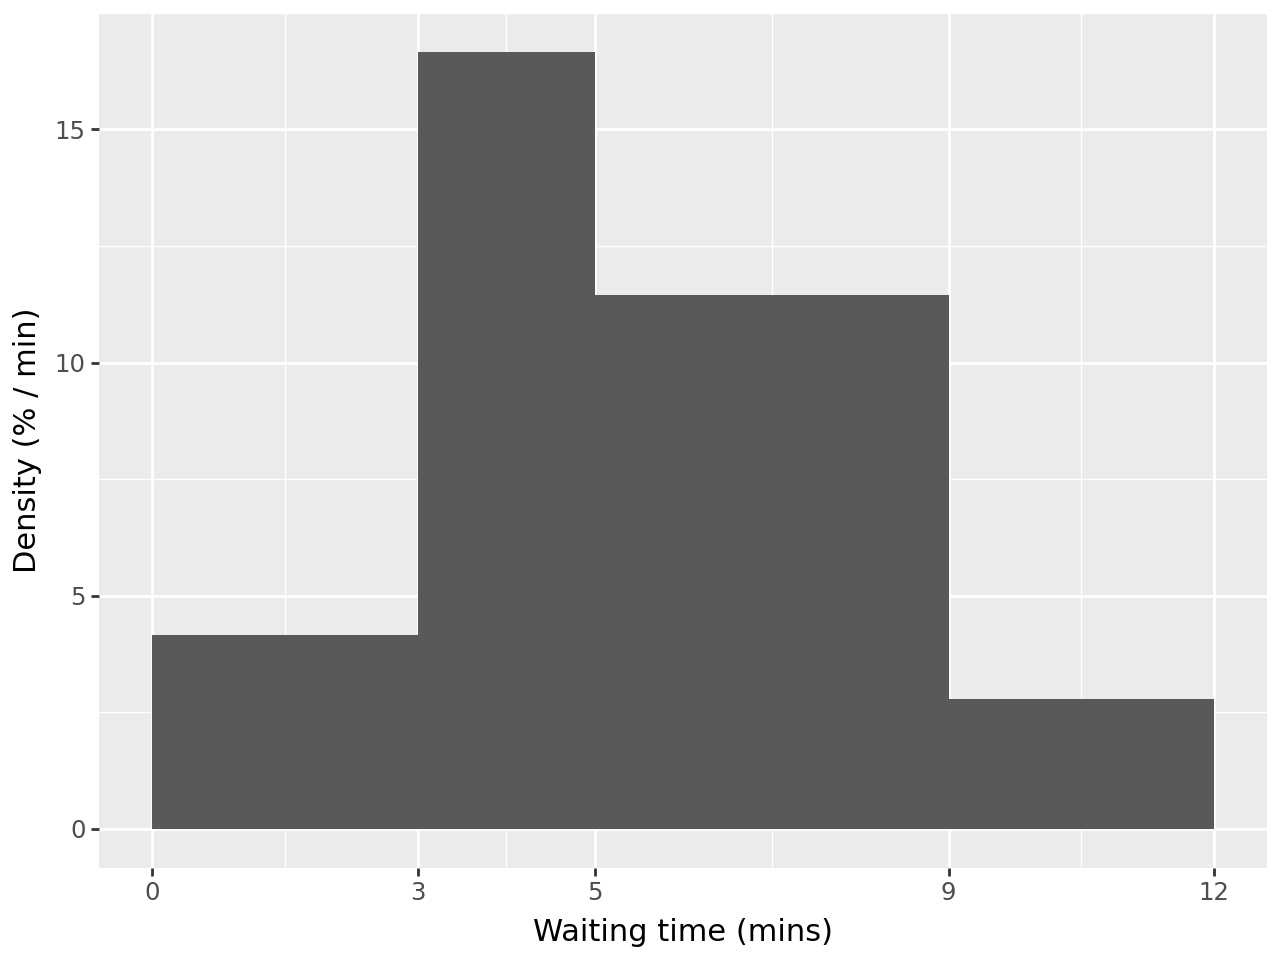

In [10]:
edges = np.array([0, 3, 5, 9, 12])
values = demo["wait_time_min"].dropna().to_numpy()
counts, _ = np.histogram(values, bins=edges)
assert counts.sum() == len(values)

bins = pd.DataFrame({
    "bin_left": edges[:-1], "bin_right": edges[1:], "n": counts
})
bins["percent"] = 100 * bins["n"] / len(values)
bins["percent_density"] = bins["percent"] / (bins["bin_right"] - bins["bin_left"])
display(bins)
print("Total area:",
      (bins["percent_density"] * (bins["bin_right"] - bins["bin_left"])).sum())

p = (
    ggplot(bins, aes(xmin="bin_left", xmax="bin_right",
                     ymin=0, ymax="percent_density"))
    + geom_rect()
    + scale_x_continuous(breaks=edges.tolist())
    + labs(x="Waiting time (mins)", y="Density (% / min)")
)
display(p)

`edges[:-1]` bỏ biên cuối để lấy mép trái; `edges[1:]` bỏ biên đầu để lấy mép phải. `np.diff(edges)` cũng cho độ rộng các khoảng. Mỗi hàng của `bins` là một khoảng; `geom_rect` vẽ nó bằng hai mép trên trục x và hai mép trên trục y.

Đối với nhiều nhóm, thực hiện bảng này *riêng trong từng nhóm*. Mẫu số phải là `len(values)` của nhóm đang xét, không phải tổng toàn bộ. Kiểm tra $\sum h_j\Delta_j$ cho từng nhóm, không chỉ kiểm tra tổng gộp.

**Cách bắt lỗi nhanh:** nếu diện tích ra 60% hoặc 150%, hãy kiểm tra số quan sát nằm ngoài biên, quy tắc đầu mút và mẫu số trước khi chỉnh màu hay độ rộng hình.

## 7. Biểu đồ cột: có bảng tần số rồi thì dùng geom_col

`geom_bar()` tự đếm từ từng quan sát; `geom_col()` lấy chiều cao từ một cột số đã tính [4]. Với cột tỉ lệ, dùng `geom_col`, không đếm lại số hàng của bảng tóm tắt.

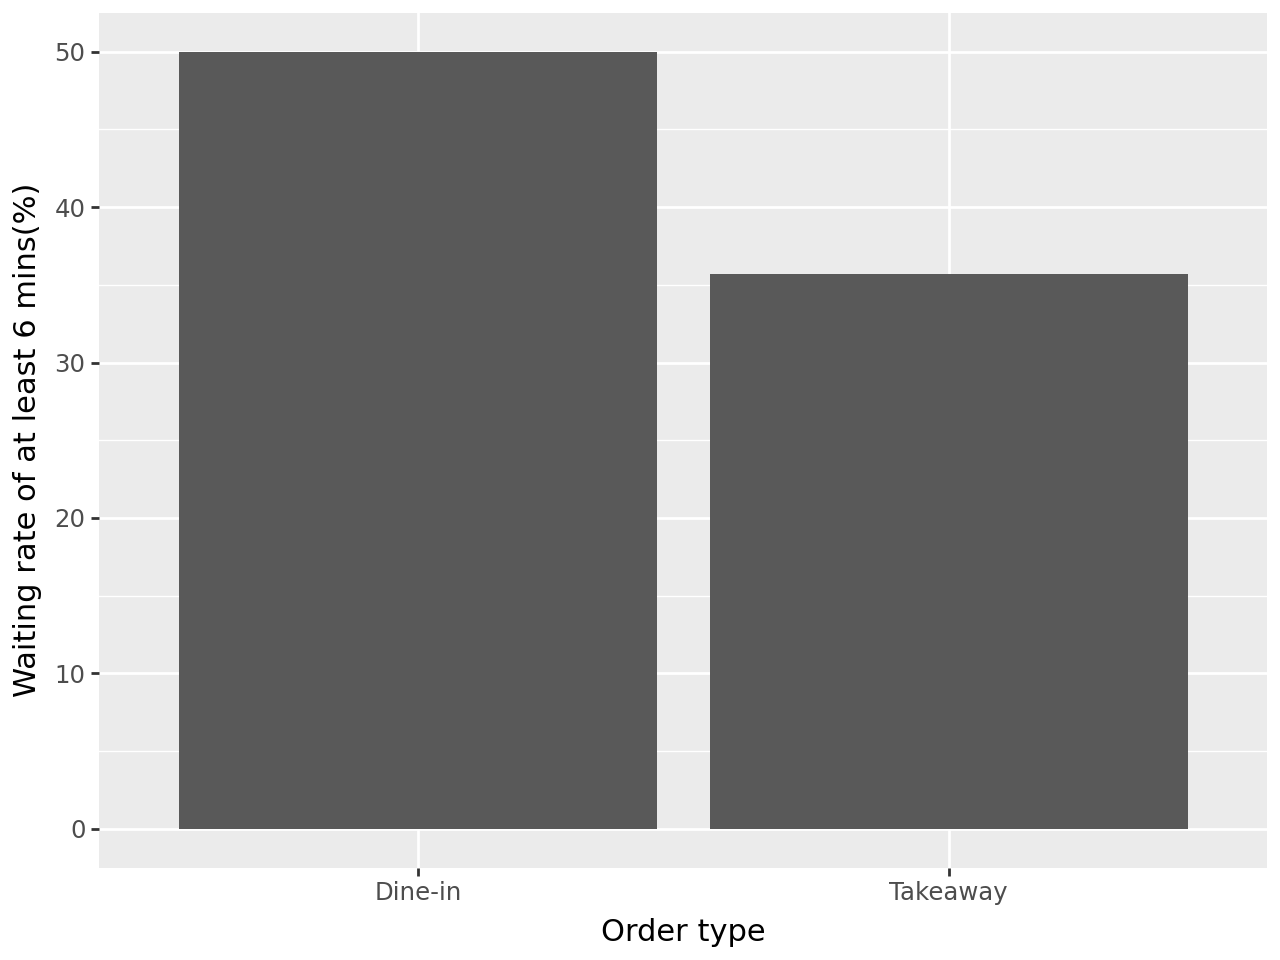

In [11]:
bang = (
    demo.groupby("order_type", observed=True)
    .agg(n=("id", "size"),
         n_long_wait=("wait_time_min", lambda s: (s >= 6).sum()))
    .reset_index()
)
bang["percent"] = 100 * bang["n_long_wait"] / bang["n"]
p = (ggplot(bang, aes(x="order_type", y="percent"))
     + geom_col()
     + labs(x="Order type", y="Waiting rate of at least 6 mins(%)"))
display(p)

Giải thích một ô bằng lời: mẫu số là tổng số đơn của kiểu đó; tử số là số đơn cùng kiểu chờ từ 6 phút trở lên. Đừng lọc chỉ các đơn chờ lâu rồi mới tính tổng đơn.

Để giữ đủ các mức rời rạc kể cả mức không xuất hiện, dùng `reindex`:

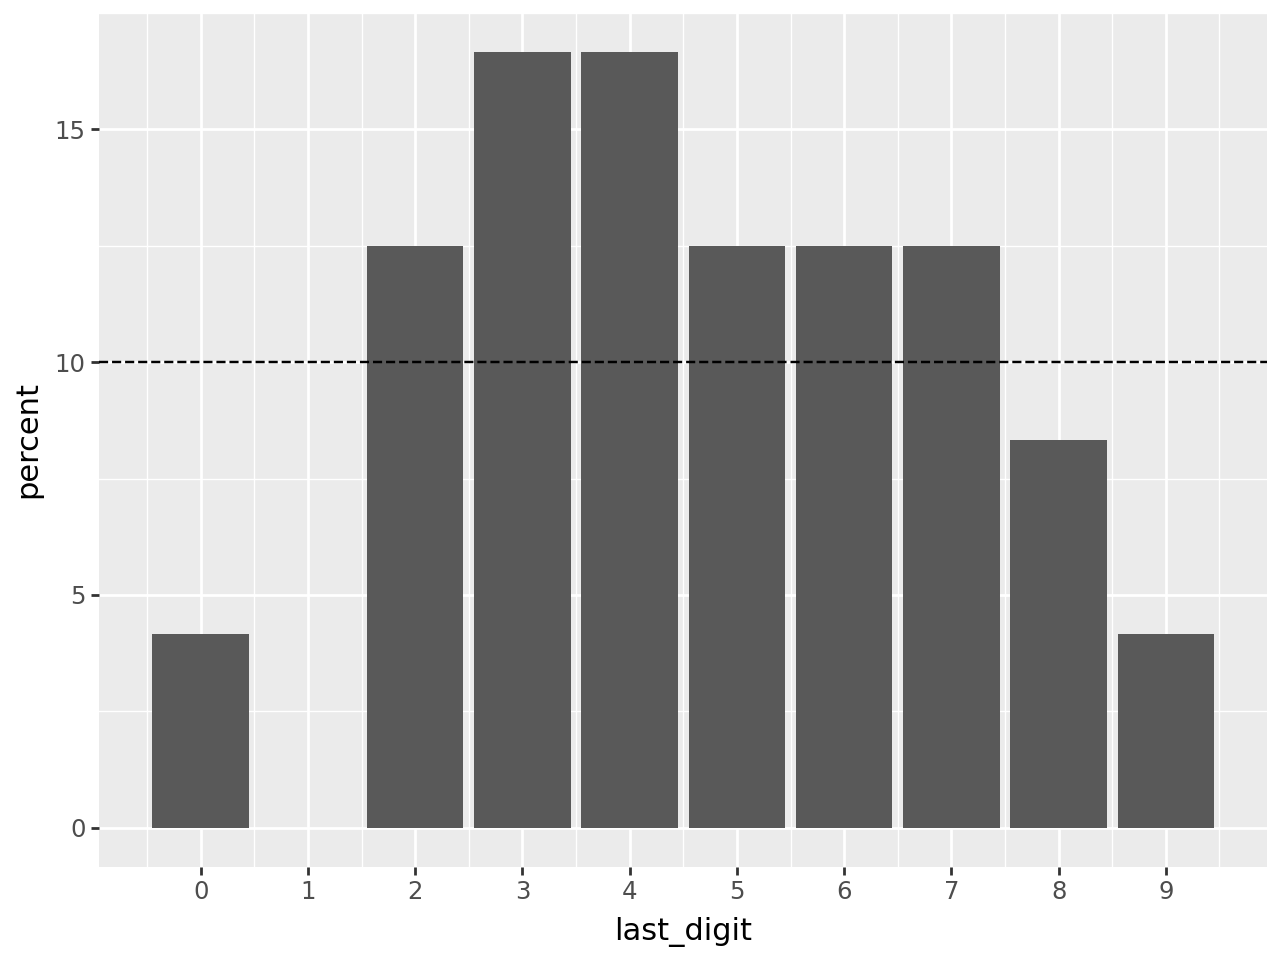

In [12]:
digit = demo["wait_time_min"].astype(int) % 10
freq = digit.value_counts().reindex(range(10), fill_value=0)
bang_digit = pd.DataFrame({"last_digit": range(10), "n": freq.to_numpy()})
bang_digit["percent"] = 100 * bang_digit["n"] / len(digit)
p = (ggplot(bang_digit, aes(x="last_digit", y="percent"))
     + geom_col() + geom_hline(yintercept=10, linetype="dashed")
     + scale_x_continuous(breaks=list(range(10))))
display(p)

Mẫu 24 đơn chỉ để học cú pháp; chưa phải minh chứng về thói quen ghi số. Trước khi đổi sang số nguyên phải kiểm tra dữ liệu thật có phải số nguyên không, không lặng lẽ cắt phần thập phân.

## 8. Chia nhóm số, chuyển dạng dài, rồi tách ô

`pd.cut` biến giá trị số thành nhãn khoảng. Cần dùng đúng cùng một quy tắc cho tử số và mẫu số:

In [13]:
x = demo.copy()
x["wait_bin"] = pd.cut(
    x["wait_time_min"], bins=[0, 3, 6, 9, 12], right=False
)
assert x["wait_bin"].notna().all()
bang = (x.groupby("wait_bin", observed=False)
        .agg(n=("id", "size")).reset_index())
bang["wait_bin"] = bang["wait_bin"].astype(str)
display(bang)

,wait_bin,n
0,"[0, 3)",3
1,"[3, 6)",11
2,"[6, 9)",8
3,"[9, 12)",2


`right=False` chọn khoảng $[a,b)$. `observed=False` có thể giữ cả các mức khoảng trống đã định nghĩa. Nếu tính tỉ lệ, dùng `n.replace(0,np.nan)` làm mẫu số để nhóm rỗng cho NA, không phải 0%.

Khi có nhiều cột đo cùng đại lượng, chuyển bảng rộng sang dài. Ví dụ độc lập:

,id,trial,time_s
0,1,trial_1,4.2
1,2,trial_1,5.1
2,3,trial_1,3.8
3,1,trial_2,3.9
4,2,trial_2,5.4
5,3,trial_2,4.0
6,1,trial_3,4.0
7,2,trial_3,5.0
8,3,trial_3,3.6


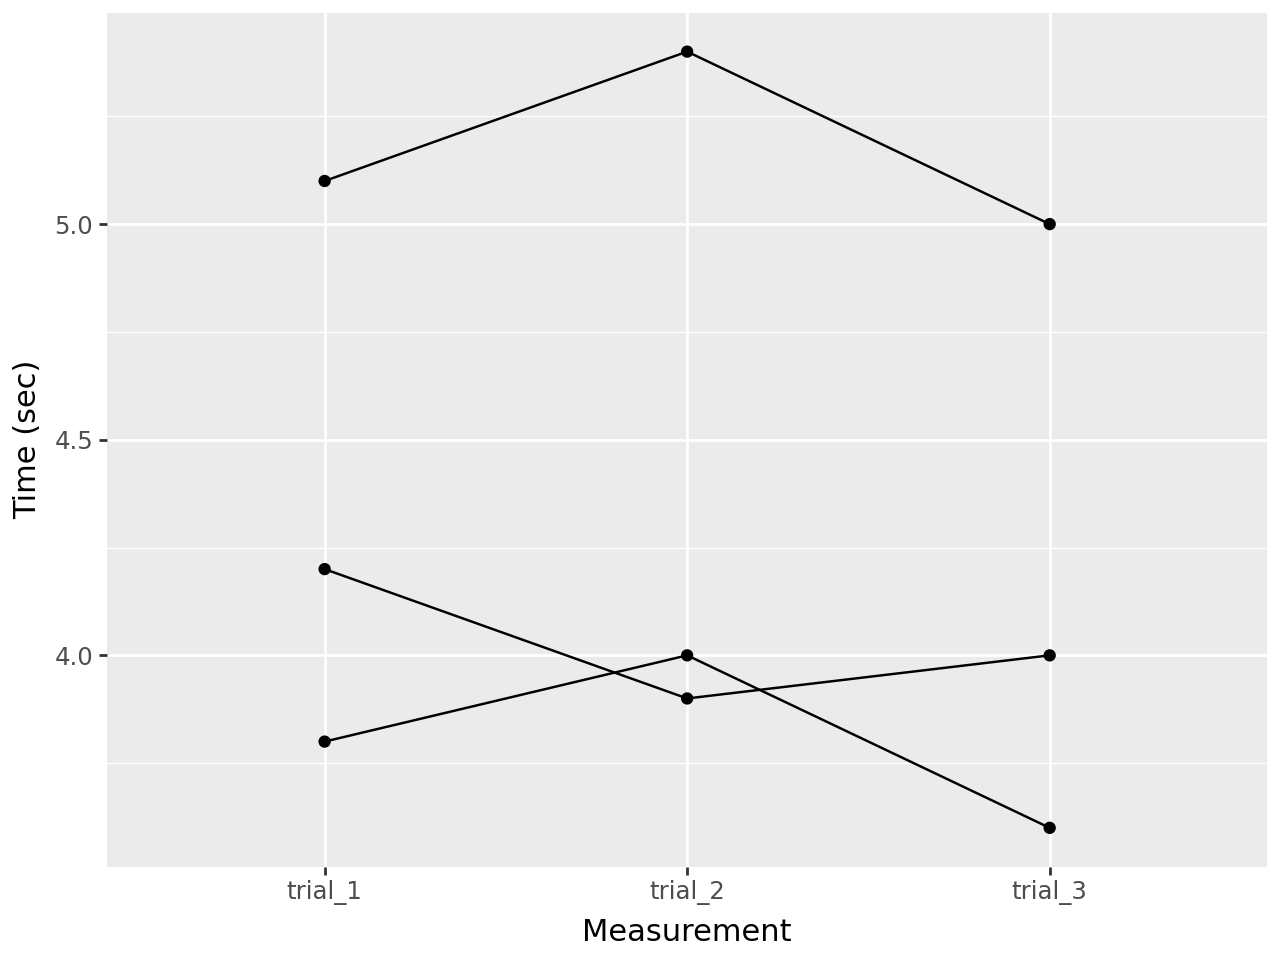

In [14]:
thu = pd.DataFrame({
    "id": [1, 2, 3], "trial_1": [4.2, 5.1, 3.8],
    "trial_2": [3.9, 5.4, 4.0], "trial_3": [4.0, 5.0, 3.6]
})
dai = thu.melt(id_vars="id", value_vars=["trial_1", "trial_2", "trial_3"],
               var_name="trial", value_name="time_s")
display(dai)
p = (ggplot(dai, aes(x="trial", y="time_s", group="id"))
     + geom_point() + geom_line()
     + labs(x="Measurement", y="Time (sec)"))
display(p)

Mỗi hàng mới là một cặp ID–lần đo. Dòng `group="id"` cho phép nối các lần đo của *cùng đơn vị*; không nối các quan sát độc lập chỉ vì chúng đứng cạnh nhau trong bảng. Trong Bài 8, dùng ý tưởng `melt` cho ba điểm thành phần rồi dùng `facet_wrap`; không cần đường nối.

## 9. Từ mã mẫu đến bài nộp của bạn

Mỗi bài Python nên có ba phần: **câu hỏi đang trả lời**, **mã và kết quả**, **nhận xét**. Không để người đọc phải suy đoán ý nghĩa của bảng hoặc ảnh.

| Bài | Nên bắt đầu từ mẫu nào? | Phần bạn phải tự quyết định/viết |
| --- | --- | --- |
| 6 | Histogram + chia ô (mục 5–6) | Bảng theo tác vụ; kiểm tra diện tích; so sánh hai phân phối. |
| 7 | Biểu đồ cột + reindex (mục 7) | Tỉ lệ chữ số theo cách ghi; giải thích cơ chế có thể xảy ra. |
| 8 | Histogram + melt (mục 5,8) | So sánh biên 5/1 điểm; kiểm tra các đợt và thành phần. |
| 9 | groupby + boxplot | Trung bình gộp/nhóm; tính trọng số; diễn giải sự đảo chiều. |
| 10 | cut + tử số/mẫu số (mục 7–8) | Không lọc mất mẫu số; so sánh số lỗi và tỉ lệ lỗi. |


**Danh mục kiểm tra trước khi nộp**


1.  Restart Kernel, chạy Run All từ đầu. Không dựa vào biến còn sót sau một lần chạy cũ.

1.  Mọi CSV được đọc từ `data/`; ghi rõ bao nhiêu hàng bị bỏ và lý do.

1.  Mọi biểu đồ có tên biến, đơn vị, biên chia khi cần; hình so sánh dùng thang đo nhất quán.

1.  Tỉ lệ luôn có tử số và mẫu số giải thích được. Nếu $n=0$, để NA và ghi lý do.

1.  Không thay dữ liệu để làm đẹp một kết luận. Các câu nhận xét dựa trên hình/bảng vừa tạo, không chép câu mẫu.

1.  Phân biệt mô tả dữ liệu giả lập, dự đoán theo giả thiết và khẳng định nguyên nhân.

**Lỗi thường gặp.** `ModuleNotFoundError`: cài bằng `%pip` trong đúng kernel. `NameError`: chạy lại ô nạp dữ liệu/nhập thư viện. `KeyError`: xem `df.columns.tolist()` và đối chiếu tên cột. Không thấy hình: dùng `display(p)`. Tỉ lệ sai: kiểm tra lọc thiếu, nhóm rỗng và mẫu số. Chỉ có chữ TODO không phải lỗi chương trình: đó là phần bài sinh viên cần bổ sung.